In [113]:
import sys

sys.path.append("..")
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from classes.feature.feature_classes import StatisticalFeatures
from classes.sample.sample_classes import (
    SampleStatisticalFeatures,
    SingleStatisticalFeaturesSample,
)
import os
import json
from typing import List

import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "ieee", "grid"])
import matplotlib.dates as mdates
import matplotlib.ticker as ticker


In [114]:
SEQ_1_PATH = Path("../data/statistical_features/sequence_1")
SEQ_2_PATH = Path("../data/statistical_features/sequence_2")
SEQ_3_PATH = Path("../data/statistical_features/sequence_3")

## Load data

In [115]:
def structure_data_to_dataframe(
    features_list: List[SampleStatisticalFeatures],
) -> pd.DataFrame:
    """
    Structure the data from a list of SampleStatisticalFeatures objects into a DataFrame.

    Args:
        features_list (List[SampleStatisticalFeatures]): List of SampleStatisticalFeatures objects.

    Returns:
        pd.DataFrame: DataFrame containing the structured data.
    """
    data = []

    for feature in features_list:
        for cable in ["sample_c1", "sample_c2", "sample_c3", "sample_c4"]:
            sample = getattr(feature, cable)
            for axis in ["x", "y", "z"]:
                axis_features = getattr(sample, axis)
                data.append(
                    {
                        "sample_id": feature.sample_id,
                        "temperature": feature.temperature,
                        "cable": cable,
                        "axis": axis,
                        "tension": sample.tension,
                        "mean": axis_features.mean,
                        "std": axis_features.std,
                        "rms": axis_features.rms,
                        "skewness": axis_features.skewness,
                        "kurtosis": axis_features.kurtosis,
                        "shape_factor": axis_features.shape_factor,
                        "crest_factor": axis_features.crest_factor,
                        "peak_to_peak": axis_features.peak_to_peak,
                        "entropy": axis_features.entropy,
                        "energy": axis_features.energy,
                    }
                )

    df = pd.DataFrame(data)
    return df

In [116]:
def load_and_transform_features(path: Path):
    files = os.listdir(path)
    features: List[SampleStatisticalFeatures] = []
    for file in files:
        with open(path / file, "r") as f:
            data = json.load(f)
        features.append(SampleStatisticalFeatures(**data))
    df = structure_data_to_dataframe(features)
    df["sampled_at"] = pd.to_datetime(df["sample_id"])
    return df

In [117]:
df_1 = load_and_transform_features(SEQ_1_PATH)
df_2 = load_and_transform_features(SEQ_2_PATH)
df_3 = load_and_transform_features(SEQ_3_PATH)

In [118]:
VALID_START_DATE_S1 = datetime(2023, 1, 15)

VALID_START_DATE_S2 = datetime(2023, 4, 27, 11)
VALID_END_DATE_S2 = datetime(2023, 7, 5, 11)

VALID_START_DATE_S3 = datetime(2023, 8, 15, 15)

SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11, 0, 0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30, 11, 0, 0)

In [119]:
SAMPLES_TO_AVOID = [
    datetime(2023, 5, 19, 19, 16),
    datetime(2023, 5, 29, 19, 16),
    datetime(2023, 6, 1, 11, 39),
]

In [120]:
df_1 = df_1.loc[df_1["sampled_at"] > VALID_START_DATE_S1].reset_index(drop=True)
df_2 = df_2.loc[
    (df_2["sampled_at"] > VALID_START_DATE_S2)
    & (df_2["sampled_at"] < VALID_END_DATE_S2)
].reset_index(drop=True)
df_3 = df_3.loc[df_3["sampled_at"] > VALID_START_DATE_S3].reset_index(drop=True)

In [121]:
df_1 = df_1.loc[~df_1["sampled_at"].isin(SAMPLES_TO_AVOID)].reset_index(drop=True)
df_2 = df_2.loc[~df_2["sampled_at"].isin(SAMPLES_TO_AVOID)].reset_index(drop=True)
df_3 = df_3.loc[~df_3["sampled_at"].isin(SAMPLES_TO_AVOID)].reset_index(drop=True)

# Tension and temperature

In [122]:
def prepare_tension_temperature_data(
    df: pd.DataFrame, axis: str = "x", cable_prefix: str = "sample_c"
) -> pd.DataFrame:
    """
    Prepare tension and temperature data from a dataframe for analysis.

    Args:
        df (pd.DataFrame): Input dataframe containing tension and temperature data
        axis (str, optional): Axis to filter on. Defaults to "x".
        cable_prefix (str, optional): Prefix for cable columns. Defaults to "sample_c".

    Returns:
        pd.DataFrame: Processed dataframe with temperature and tension data

    Raises:
        ValueError: If required columns are missing
        KeyError: If specified axis or cables are not found
    """
    required_cols = ["sampled_at", "temperature", "cable", "axis", "tension"]
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    # Get temperature data
    temp_data = df.loc[
        (df["axis"] == axis) & (df["cable"] == f"{cable_prefix}1"),
        ["sampled_at", "temperature"],
    ].set_index("sampled_at")

    if temp_data.empty:
        raise KeyError(f"No data found for axis '{axis}' and cable '{cable_prefix}1'")

    # Get tension data
    tens_data = df.loc[df["axis"] == axis][["sampled_at", "cable", "tension"]]
    if tens_data.empty:
        raise KeyError(f"No tension data found for axis '{axis}'")

    # Pivot tension data
    tens_data = tens_data.pivot(columns="cable", index="sampled_at", values="tension")

    # Merge temperature and tension data
    result = pd.merge(
        temp_data, tens_data, left_index=True, right_index=True
    ).reset_index()

    return result

In [123]:
full_1 = prepare_tension_temperature_data(df_1)
full_2 = prepare_tension_temperature_data(df_2)
full_3 = prepare_tension_temperature_data(df_3)

In [124]:
def plot_tension_temperature(df, sequence):
    """
    Create tension and temperature plots for the input dataframe.

    Args:
        df (pd.DataFrame): DataFrame containing sampled_at, temperature, and sample_c1-4 columns
        sequence (int): Sequence number for file naming
    """
    # Using a more professional color palette
    # colors = ["b", "g", "r", "c"]  # Blue, Green, Red, Cyan

    # Plot average tension
    fig, ax = plt.subplots(figsize=(5, 2))
    ax.plot(df["sampled_at"], df["sample_c1"])  # , color=colors[0])
    ax.plot(df["sampled_at"], df["sample_c2"])  # , color=colors[1])
    ax.plot(df["sampled_at"], df["sample_c3"])  # , color=colors[2])
    ax.plot(df["sampled_at"], df["sample_c4"])  # , color=colors[3])

    ax.set_xlabel("Measurement date")
    ax.set_ylabel("Average tension (N)")
    ax.set_ylim(1200, 2800)
    # ax.legend(["$\\bar{t}^{(c_1)}$", "$\\bar{t}^{(c_2)}$", "$\\bar{t}^{(c_3)}$", "$\\bar{t}^{(c_4)}$"])
    ax.legend(["Cable 1", "Cable 2", "Cable 3", "Cable 4"])

    ax.grid(True)

    # Set the locator with MultipleLocator
    ax.xaxis.set_major_locator(ticker.MultipleLocator(7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(f"figures_eda/avg_tension_seq{sequence}.png", dpi=300)

    ## Plot temperature
    fig, ax = plt.subplots(figsize=(5, 2))
    ax.plot(
        df["sampled_at"], df["temperature"], color="k"
    )  # Using black for temperature
    ax.set_xlabel("Measurement date")
    ax.set_ylabel("Temperature (ºC)")
    ax.set_ylim(12.5, 40)
    # ax.legend(["$T$"])
    ax.grid(True)

    # Set the locator with MultipleLocator
    ax.xaxis.set_major_locator(ticker.MultipleLocator(7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(f"figures_eda/temperature_seq{sequence}.png", dpi=300)

    plt.show()

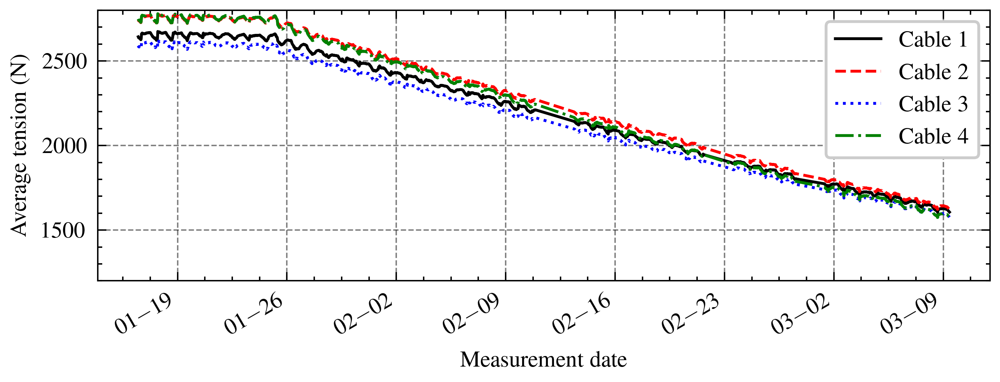

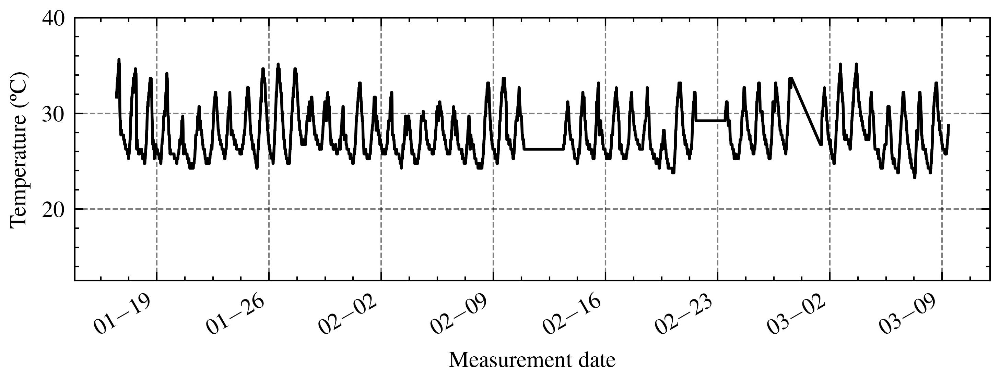

In [125]:
plot_tension_temperature(full_1, 1)

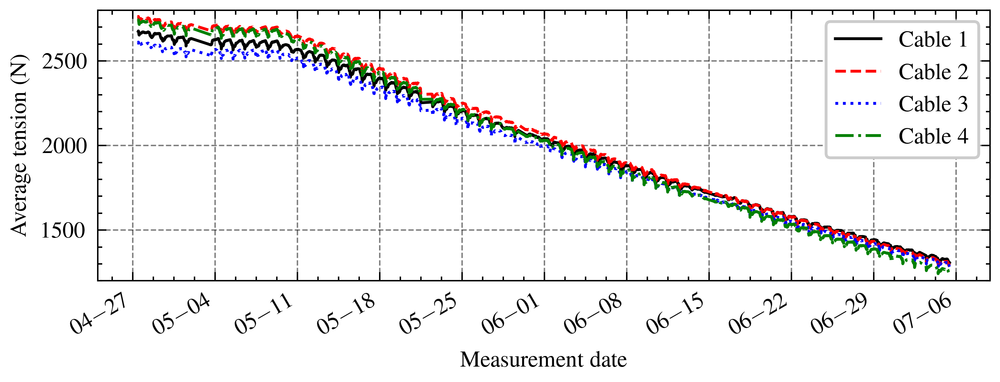

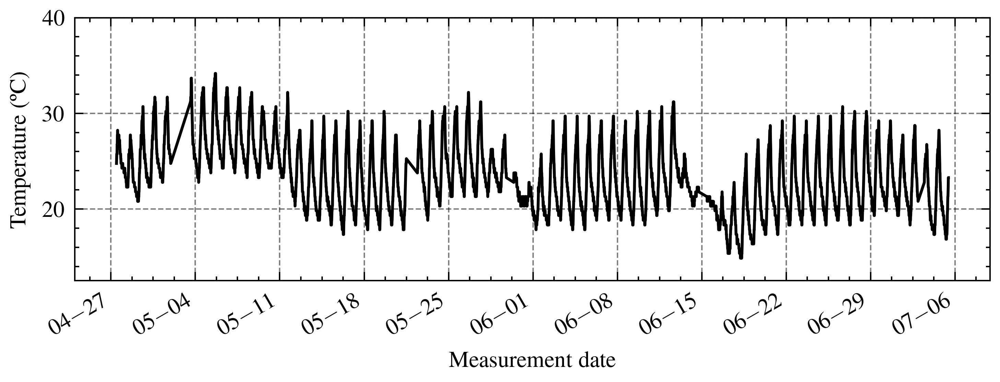

In [126]:
plot_tension_temperature(full_2, 2)

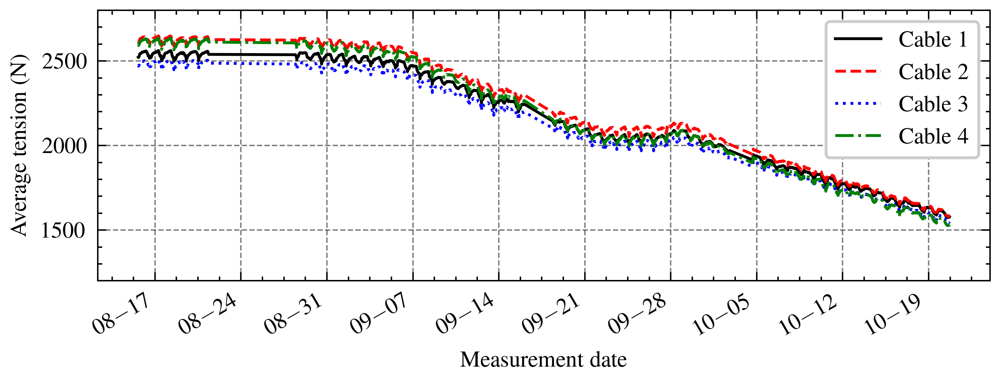

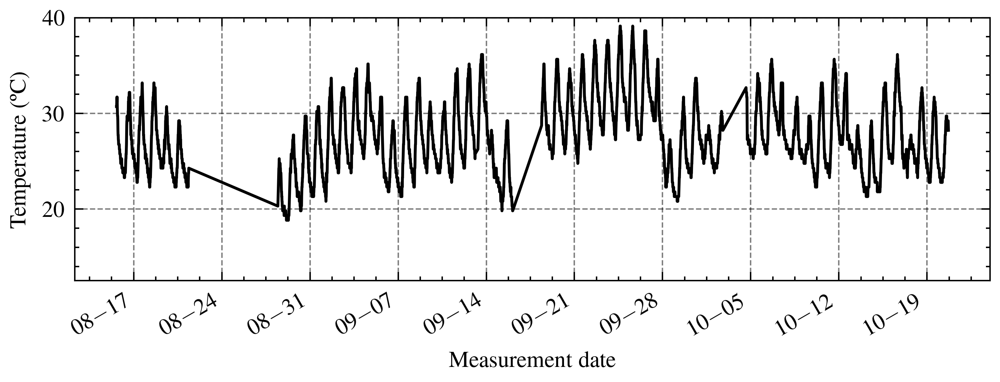

In [127]:
plot_tension_temperature(full_3, 3)

In [128]:
len(full_1), len(full_2), len(full_3)

(4405, 6210, 5246)

In [129]:
# filter data

full_1_filtered = full_1[full_1["sampled_at"] <= SEQ_1_HEALTH_END]

full_2_filtered = full_2[full_2["sampled_at"] <= SEQ_2_HEALTH_END]

full_3_filtered = full_3[full_3["sampled_at"] <= SEQ_3_HEALTH_END]


full_1_dmg = full_1[full_1["sampled_at"] > SEQ_1_HEALTH_END]

full_2_dmg = full_2[full_2["sampled_at"] > SEQ_2_HEALTH_END]

full_3_dmg = full_3[full_3["sampled_at"] > SEQ_3_HEALTH_END]

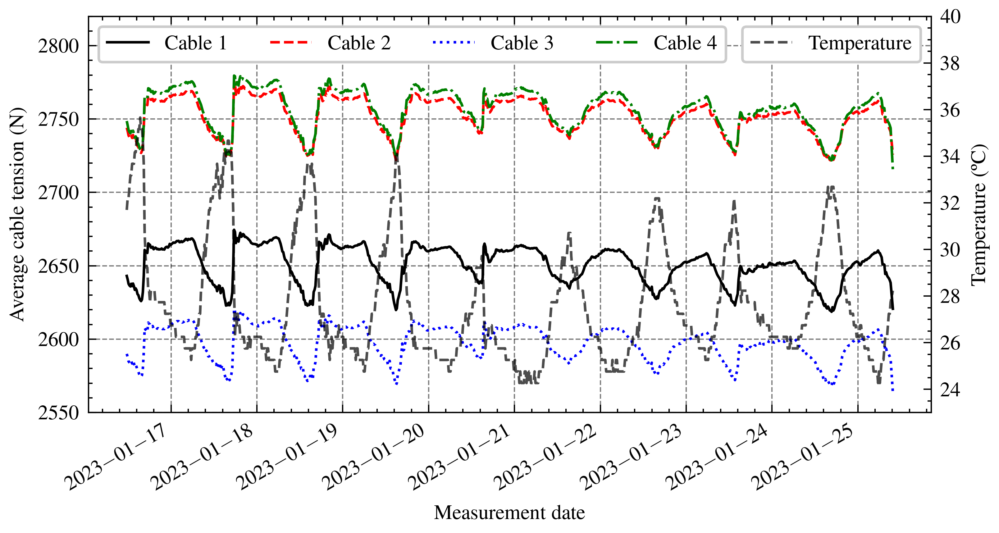

In [130]:
# full_1_filtered = full_1[
#     (full_1["sampled_at"] >= datetime(2023, 2, 1))
#     & (full_1["sampled_at"] <= datetime(2023, 2, 8))
# ]

fig, ax1 = plt.subplots(figsize=(5.5, 3))

# Plot sensor values on primary y-axis
ax1.plot(
    full_1_filtered["sampled_at"],
    full_1_filtered["sample_c1"],
    label="Cable 1",
    # color="b",
)
ax1.plot(
    full_1_filtered["sampled_at"],
    full_1_filtered["sample_c2"],
    label="Cable 2",
    # color="g",
)
ax1.plot(
    full_1_filtered["sampled_at"],
    full_1_filtered["sample_c3"],
    label="Cable 3",
    # color="r",
)
ax1.plot(
    full_1_filtered["sampled_at"],
    full_1_filtered["sample_c4"],
    label="Cable 4",
    # color="c",
)
ax1.set_xlabel("Measurement date")
ax1.set_ylabel("Average cable tension (N)")
ax1.legend(loc="upper left", ncol=4)
# ax1.grid(True, alpha=0.3)

# Set the locator with MultipleLocator
ax1.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax1.get_xticklabels(), rotation=30, ha="right")
plt.ylim([2550, 2820])
# plt.xlim(left=datetime(2023,1,14))

# Create secondary y-axis for temperature
ax2 = ax1.twinx()
ax2.plot(
    full_1_filtered["sampled_at"],
    full_1_filtered["temperature"],
    label="Temperature",
    color="k",
    linestyle="--",
    alpha=0.7,
)
ax2.set_ylabel("Temperature (ºC)")
ax2.legend(loc="upper right")
ax2.set_ylim([23, 40])
ax2.grid(False)
plt.tight_layout()
plt.savefig(f"figures_eda/temperature_tension_comparison_seq1.png", dpi=300)
plt.show()

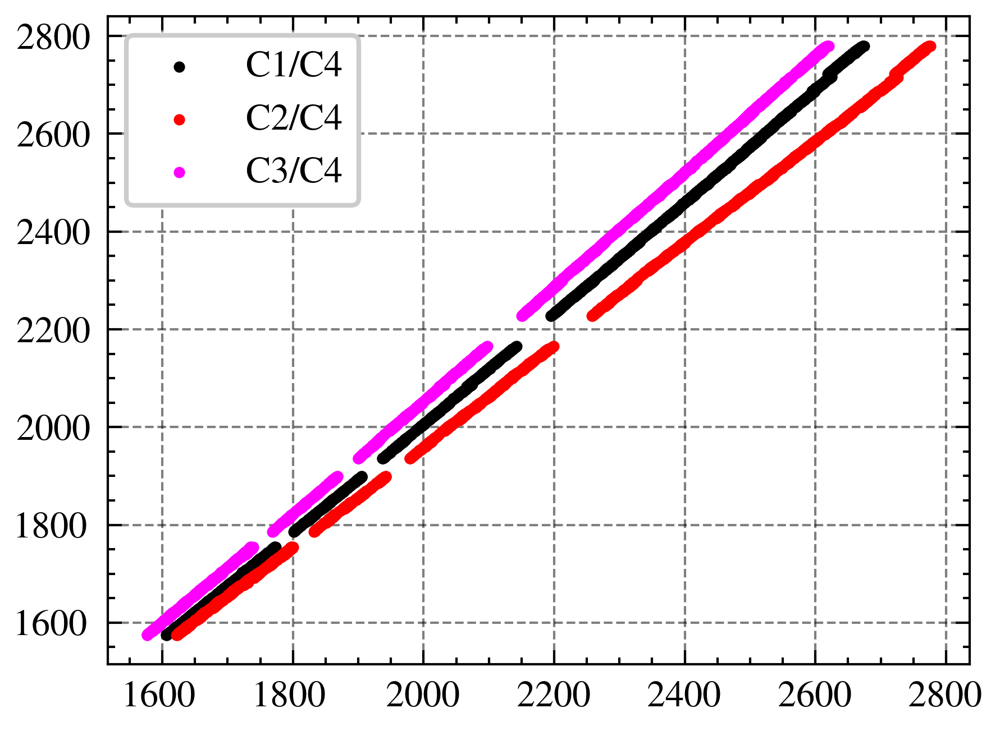

In [131]:
plt.scatter(full_1["sample_c1"], full_1["sample_c4"], s=2)
plt.scatter(full_1["sample_c2"], full_1["sample_c4"], s=2)
plt.scatter(full_1["sample_c3"], full_1["sample_c4"], s=2, c="magenta")

# plt.ylim(2550, 2820)
# plt.xlim(2550, 2820)
plt.legend(["C1/C4", "C2/C4", "C3/C4"])
plt.show()

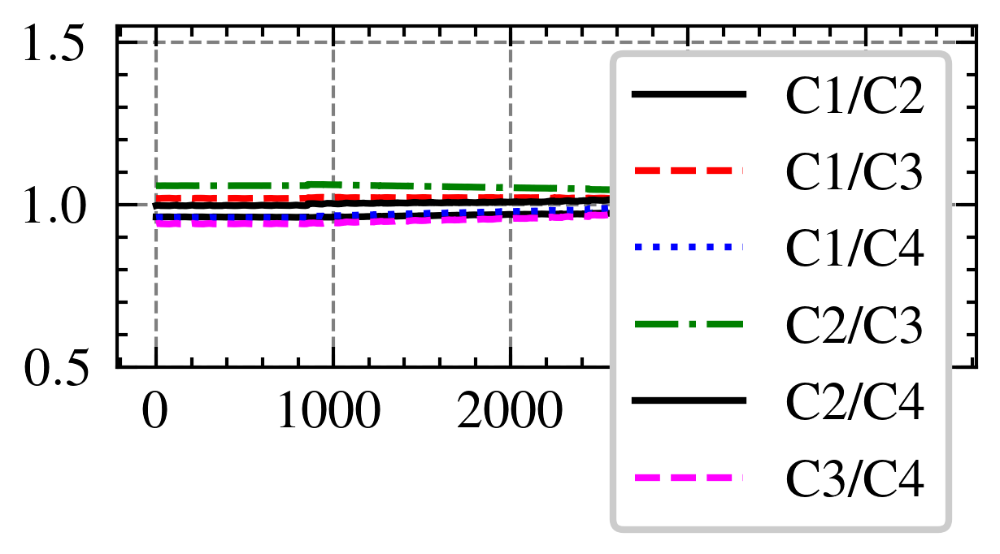

In [132]:
plt.figure(figsize=(5, 2))

plt.subplot(2, 2, 1)
plt.plot(full_1["sample_c1"] / full_1["sample_c2"])
plt.plot(full_1["sample_c1"] / full_1["sample_c3"])
plt.plot(full_1["sample_c1"] / full_1["sample_c4"])

plt.plot(full_1["sample_c2"] / full_1["sample_c3"])
plt.plot(full_1["sample_c2"] / full_1["sample_c4"])
plt.plot(full_1["sample_c3"] / full_1["sample_c4"], c="magenta")
plt.ylim(0.5, 1.55)
plt.legend(["C1/C2", "C1/C3", "C1/C4", "C2/C3", "C2/C4", "C3/C4"])

# plt.plot(full_1["sample_c1"]/full_1["sample_c3"])
# plt.plot(full_1["sample_c1"]/full_1["sample_c4"])

# Vibration Statistical Features

In [133]:
def plot_variable_over_time(df, variable_to_be_plotted, sequence):
    """
    Create a 2x2 plot for the specified variable over time for each cable.

    Args:
        df (pd.DataFrame): DataFrame containing sampled_at, axis, cable, and the variable to be plotted.
        variable_to_be_plotted (str): The variable to be plotted (e.g., "rms").
        sequence (int): Sequence number for file naming.
    """
    # Variable mapping
    variable_mapping = {
        "rms": "RMS (g)",
        "skewness": "Skewness",
        "kurtosis": "Kurtosis",
        "shape_factor": "Shape Factor",
        "crest_factor": "Crest Factor",
        "peak_to_peak": "Peak to Peak (g)",
        "entropy": "Entropy",
    }

    # Filter data for each cable
    cables = ["c1", "c2", "c3", "c4"]
    fig, axs = plt.subplots(2, 2, figsize=(6, 4), sharex=True, sharey=True)

    # Define the color palette
    # colors = ["g", "b", "r", "c"]  # Green, Blue, Red, Cyan
    avg_tension = (
        df.loc[df["axis"] == "x"]
        .groupby(["sampled_at", "cable"])["tension"]
        .mean()
        .reset_index()
    )
    for i, cable in enumerate(cables):
        ax = axs[i // 2, i % 2]
        cable_data = df[df["cable"] == f"sample_{cable}"]
        tension_cable_data = avg_tension[avg_tension["cable"] == f"sample_{cable}"]
        for j, axis in enumerate(cable_data["axis"].unique()):
            axis_data = cable_data[cable_data["axis"] == axis]
            ax.plot(
                axis_data["sampled_at"],
                axis_data[variable_to_be_plotted],
                label=f"{axis}",
                linestyle="-",
                # color=colors[j],
            )
        ax.set_xlabel("Measurement date")
        ax.set_ylabel(variable_mapping.get(variable_to_be_plotted))
        ax.set_ylim(0, cable_data[variable_to_be_plotted].max() * 1.25)
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.3)
        ax.set_title(f"Cable {i + 1}")

        # Set the locator with MultipleLocator
        ax.xaxis.set_major_locator(ticker.MultipleLocator(14))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

        # Create secondary y-axis for temperature
        ax2 = ax.twinx()
        ax2.plot(
            tension_cable_data["sampled_at"],
            tension_cable_data["tension"],
            label="Tension",
            color="gray",
            linestyle="-",
        )
        ax2.set_ylabel("Average cable tension (N)")
        ax2.grid(False)
        ax2.set_ylim(top=tension_cable_data["tension"].max() * 1.25)
        ax2.legend(loc="upper left")

    plt.tight_layout()
    plt.savefig(f"figures_eda/{variable_to_be_plotted}_seq{sequence}.png", dpi=300)
    plt.show()

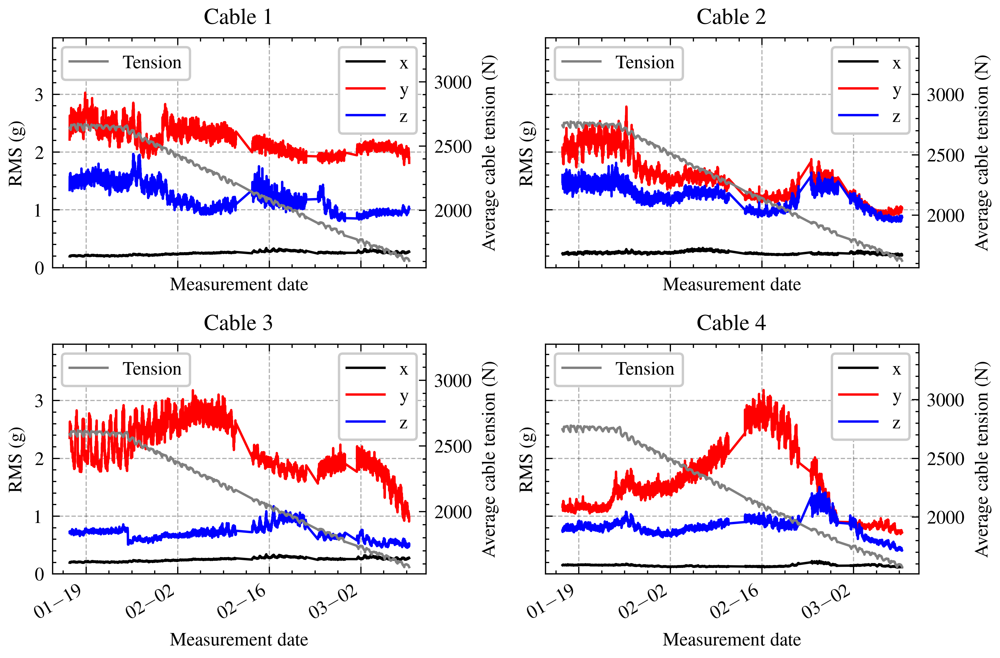

In [134]:
plot_variable_over_time(df_1, "rms", sequence=1)

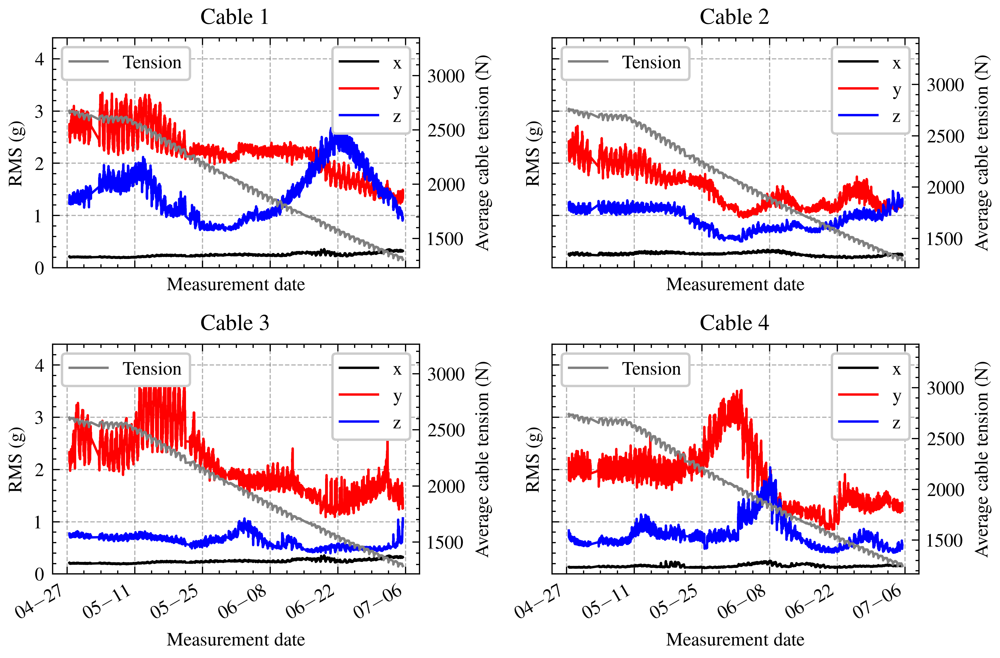

In [135]:
plot_variable_over_time(df_2, "rms", sequence=2)

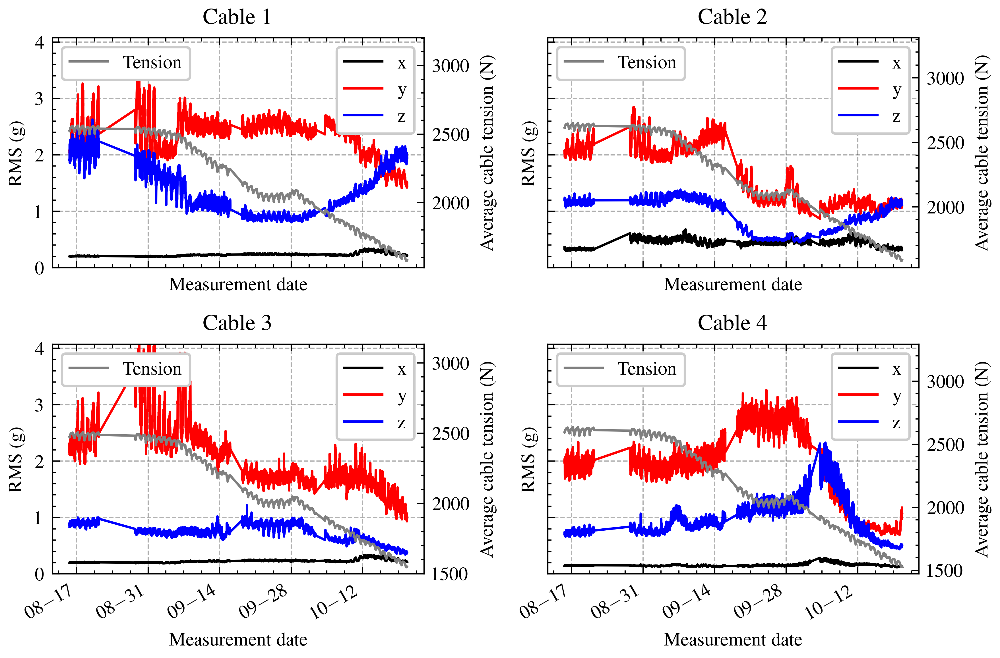

In [136]:
plot_variable_over_time(df_3, "rms", sequence=3)

## RMS per axis and cable and sequence VS tension

In [137]:
def plot_variable_over_tension(df, variable_to_be_plotted, sequence):
    """
    Create a 2x2 plot for the specified variable over time for each cable.

    Args:
        df (pd.DataFrame): DataFrame containing sampled_at, axis, cable, and the variable to be plotted.
        variable_to_be_plotted (str): The variable to be plotted (e.g., "rms").
        sequence (int): Sequence number for file naming.
    """
    # Variable mapping
    variable_mapping = {
        "rms": "RMS (g)",
        "skewness": "Skewness",
        "kurtosis": "Kurtosis",
        "shape_factor": "Shape Factor",
        "crest_factor": "Crest Factor",
        "peak_to_peak": "Peak to Peak (g)",
        "entropy": "Entropy",
    }

    # Filter data for each cable
    cables = ["c1", "c2", "c3", "c4"]
    fig, axs = plt.subplots(1, 4, figsize=(10, 3), sharex=True, sharey=True)

    # Define the color palette
    # colors = ["g", "b", "r", "c"]  # Green, Blue, Red, Cyan
    avg_tension = (
        df.loc[df["axis"] == "x"]
        .groupby(["sampled_at", "cable"])["tension"]
        .mean()
        .reset_index()
    )
    for i, cable in enumerate(cables):
        ax = axs[i]
        cable_data = df[df["cable"] == f"sample_{cable}"]
        tension_cable_data = avg_tension[avg_tension["cable"] == f"sample_{cable}"]
        for j, axis in enumerate(cable_data["axis"].unique()):
            axis_data = cable_data[cable_data["axis"] == axis]
            ax.plot(
                axis_data["tension"],
                axis_data[variable_to_be_plotted],
                label=f"Axis {axis}",
                # color=colors[j],
                linestyle="-",
                alpha=1.0,
            )
        ax.set_xlabel("Tension (N)")
        ax.set_ylabel(variable_mapping.get(variable_to_be_plotted))
        ax.set_xlim(1500, 2800)
        ax.legend(loc="upper left")
        ax.grid(True, alpha=1)
        ax.set_title(f"Cable {i + 1}")

    plt.tight_layout()
    plt.savefig(f"figures_eda/{variable_to_be_plotted}xtension_seq{sequence}.png")
    plt.show()

In [138]:
df_1["sequence"] = "1"
df_2["sequence"] = "2"
df_3["sequence"] = "3"

In [139]:
df = pd.concat([df_1, df_2, df_3]).reset_index(drop=True)

In [140]:
def new_plot_variable_over_tension(df, variable_to_be_plotted):
    """
    Create a 4x3 grid of plots: rows = cables (1-4), columns = sequences (1-3).
    Each subplot shows the specified variable vs tension for the 3 axes (x, y, z).

    Args:
        df (pd.DataFrame): DataFrame with columns ['cable', 'sequence', 'axis', 'tension', variable_to_be_plotted].
        variable_to_be_plotted (str): Variable to plot (e.g., 'rms').
    """
    # Variable mapping for labels
    variable_mapping = {
        "rms": "RMS (g)",
        "skewness": "Skewness",
        "kurtosis": "Kurtosis",
        "shape_factor": "Shape Factor",
        "crest_factor": "Crest Factor",
        "peak_to_peak": "Peak to Peak (g)",
        "entropy": "Entropy",
        "energy": "Energy",
        "mean": "Mean",
        "std": "Standard Deviation",
    }

    cables = sorted(df["cable"].unique())  # [1,2,3,4]
    sequences = sorted(df["sequence"].unique())  # [1,2,3]
    axes = sorted(df["axis"].unique())  # [x,y,z]

    fig, axs = plt.subplots(4, 3, figsize=(6, 8), sharex=True, sharey=True)

    for i, cable in enumerate(cables):
        cable_data = df[df["cable"] == cable]
        for j, seq in enumerate(sequences):
            ax = axs[i, j]
            seq_data = cable_data[cable_data["sequence"] == seq]
            # Plot 3 axes in the same subplot
            for axis in axes:
                axis_data = seq_data[seq_data["axis"] == axis]
                ax.plot(
                    axis_data["tension"],
                    axis_data[variable_to_be_plotted],
                    label=f"{axis}",
                    alpha=0.9,
                )
            if i == 3:  # bottom row
                ax.set_xlabel("Tension (N)")
            if j == 0:  # first column
                ax.set_ylabel(
                    variable_mapping.get(variable_to_be_plotted, variable_to_be_plotted)
                )
            ax.set_title(f"Cable {i + 1} - Sequence {seq}", fontsize=10)
            ax.grid(True, alpha=0.7)
            if i == 0 and j == 2:  # show legend only in the top-right subplot
                ax.legend(loc="upper right", fontsize=7, ncol=3)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(
        f"figures_eda/{variable_to_be_plotted}_vs_tension_all_sequences.png", dpi=300
    )
    plt.show()

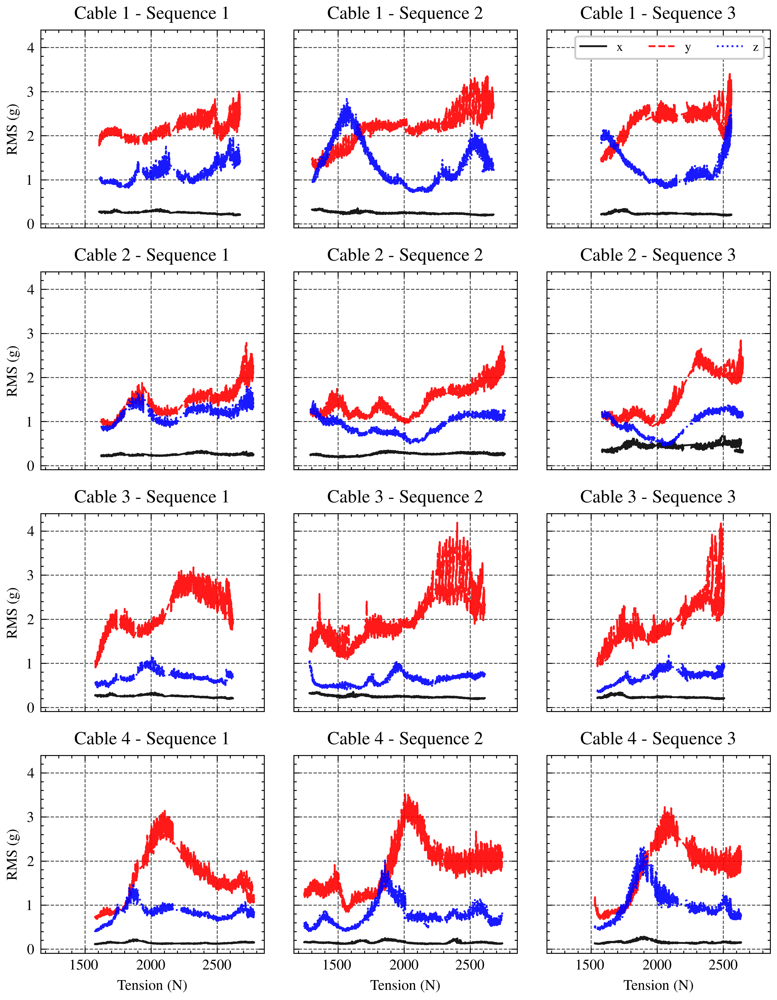

In [141]:
new_plot_variable_over_tension(df, "rms")
# plot_variable_over_tension(df_2, "rms", sequence=2)
# plot_variable_over_tension(df_3, "rms", sequence=3)

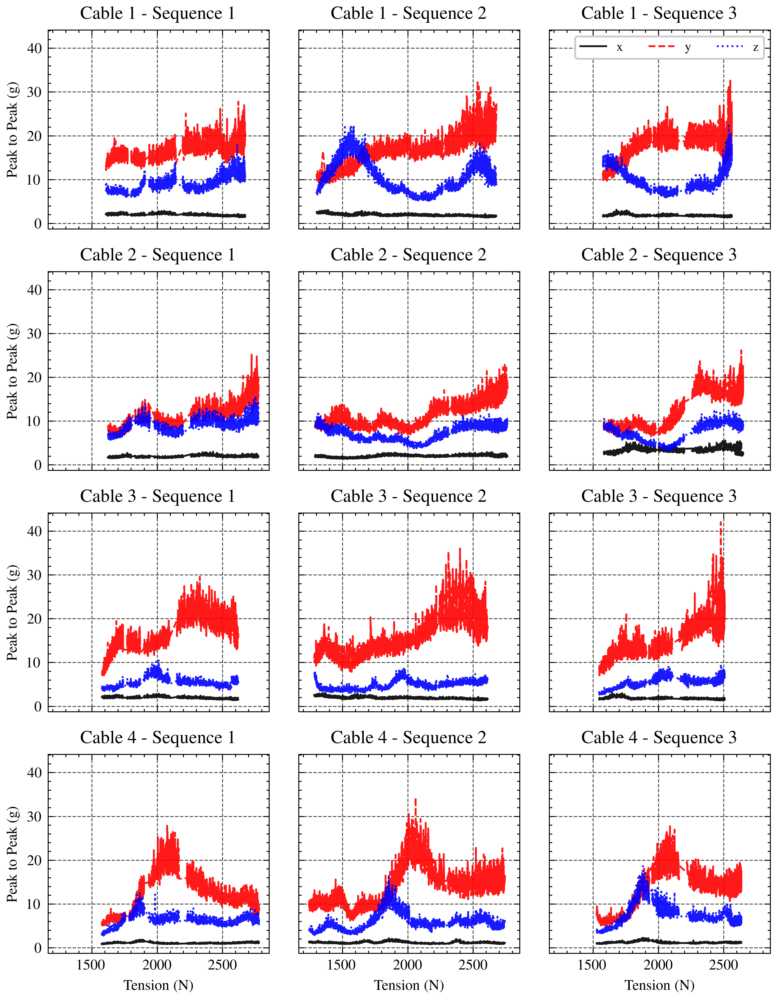

In [142]:
new_plot_variable_over_tension(df, "peak_to_peak")
# plot_variable_over_tension(df_2, "kurtosis", sequence=2)
# plot_variable_over_tension(df_3, "kurtosis", sequence=3)

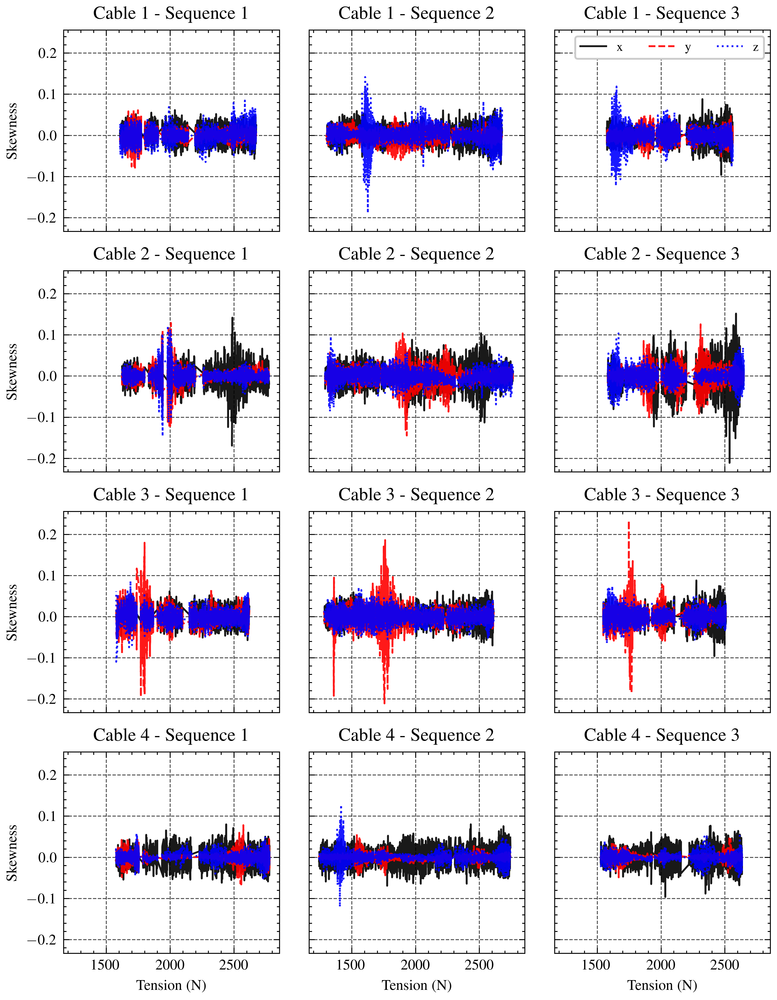

In [143]:
new_plot_variable_over_tension(df, "skewness")


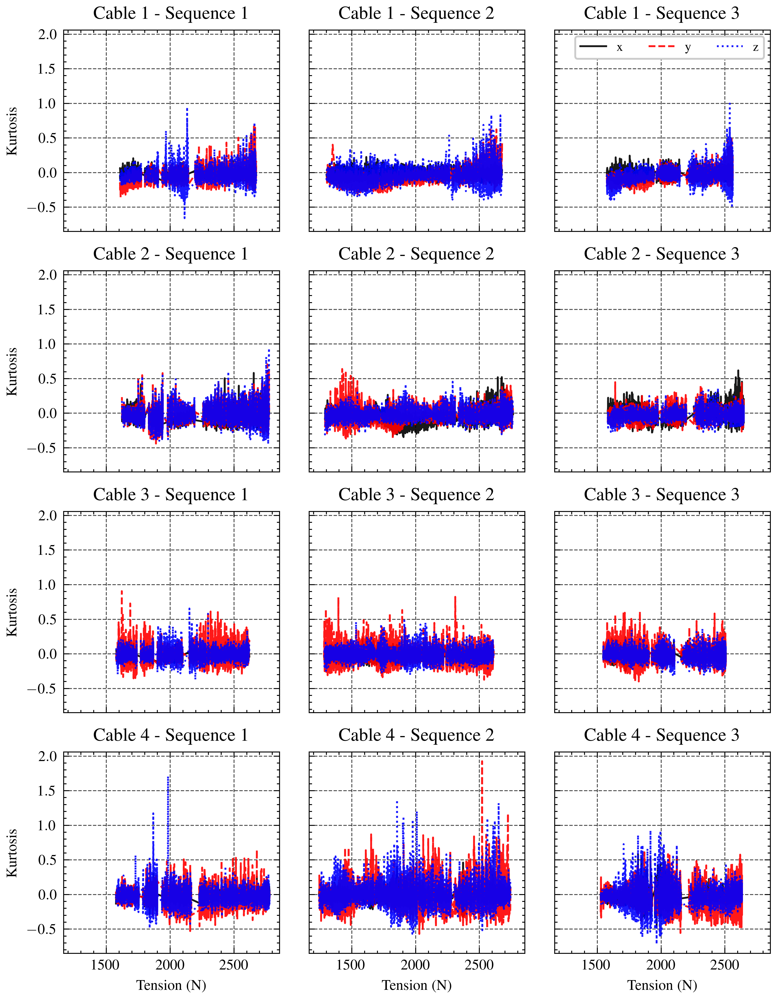

In [144]:
new_plot_variable_over_tension(df, "kurtosis")

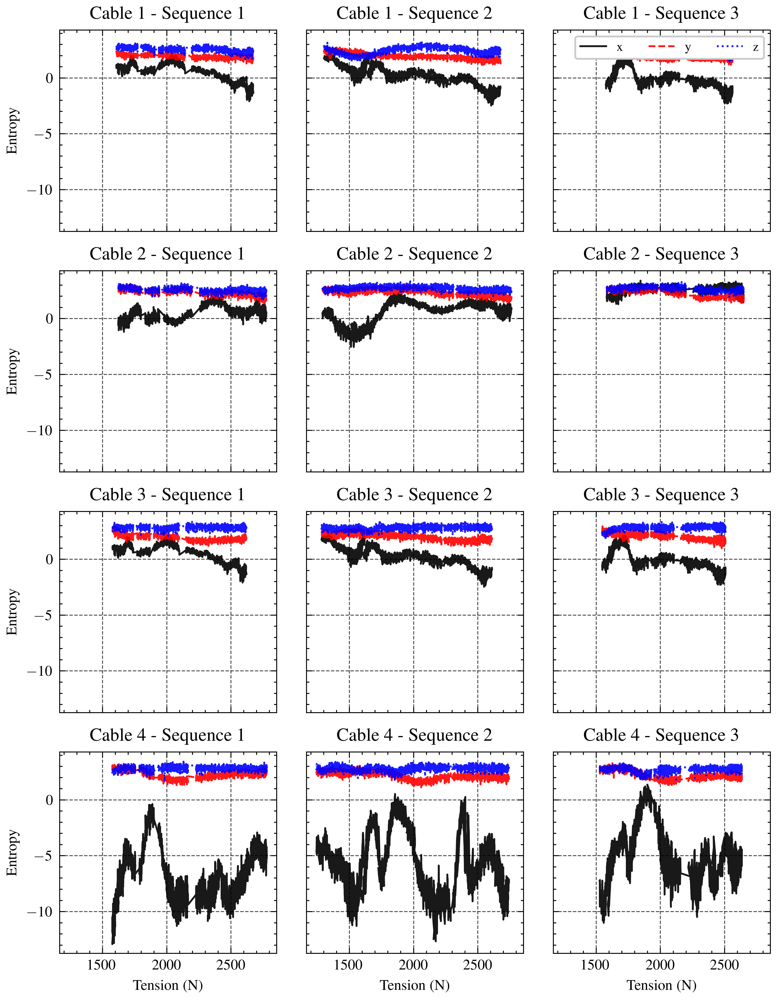

In [145]:
new_plot_variable_over_tension(df, "entropy")

In [33]:
# plot_variable_over_tension(df_1, "peak_to_peak", sequence=1)
# plot_variable_over_tension(df_2, "peak_to_peak", sequence=2)
# plot_variable_over_tension(df_3, "peak_to_peak", sequence=3)

In [34]:
# plot_variable_over_tension(df_1, "skewness", sequence=1)
# plot_variable_over_tension(df_2, "skewness", sequence=2)
# plot_variable_over_tension(df_3, "skewness", sequence=3)

In [35]:
def get_rms(data: List[float]) -> float:
    """
    Calculate the root mean square (RMS) of the input data.

    Args:
        data (List[float]): List of data points.

    Returns:
        float: Root mean square (RMS) of the input data.
    """
    return np.sqrt(np.mean(np.array(data) ** 2))

In [36]:
df_list = [df_1, df_2, df_3]

In [ ]:
def plot_comparison_over_tension(df_list, variable_to_be_plotted: str, title: str = ""):
    """
    Create a 2x2 plot for the specified variable over time for each cable.

    Args:
        df (pd.DataFrame): DataFrame containing sampled_at, axis, cable, and the variable to be plotted.
        variable_to_be_plotted (str): The variable to be plotted (e.g., "rms").
        sequence (int): Sequence number for file naming.
    """
    # Variable mapping
    variable_mapping = {
        "rms": "RMS (g)",
        "skewness": "Skewness",
        "kurtosis": "Kurtosis",
        "shape_factor": "Shape Factor",
        "crest_factor": "Crest Factor",
        "peak_to_peak": "Peak to Peak (g)",
        "entropy": "Entropy",
    }
    
    grouped = [
        df.groupby(["sample_id", "tension", "cable"])[variable_to_be_plotted]
        .apply(get_rms)
        .reset_index()
        for df in df_list
    ]
    cables = ["c1", "c2", "c3", "c4"]
    fig, axs = plt.subplots(2, 2, figsize=(5, 4), sharex=True, sharey=True)

    # Only show legend in the first subplot (top-left)
    legend_ax = axs[0, 0]

    max_val = max(df[variable_to_be_plotted].max() for df in grouped)
    for i, cable in enumerate(cables):
        ax = axs[i // 2, i % 2]
        # maxval = 0
        for j, df in enumerate(grouped):
            cable_data = df[df["cable"] == f"sample_{cable}"].sort_values("tension")
            ax.scatter(
                cable_data["tension"],
                cable_data[variable_to_be_plotted],
                label=f"Seq. {j + 1}",
                #linestyle="-",
                alpha=0.75,
                s=1
            )
           
        # Only set x-label for bottom row
        if i // 2 == 1:
            ax.set_xlabel("Tension (N)")
        else:
            ax.set_xlabel("")
        # Only set y-label for left column
        if i % 2 == 0:
            ax.set_ylabel(variable_mapping.get(variable_to_be_plotted))
        else:
            ax.set_ylabel("")
        ax.grid(True, alpha=1)
        ax.set_title(f"Cable {i + 1}")
        if max_val > 0:
            ax.set_ylim(0, max_val * 1.2)
        # Only add legend to the first subplot
        if ax is legend_ax:
            handles, labels = ax.get_legend_handles_labels()
            ax.legend(
                handles, labels,
                loc="upper center",
                # bbox_to_anchor=(0.5, -0.25),
                ncol=3,
                # frameon=False,
                fontsize=6,
            )

    plt.tight_layout()
    plt.savefig(f"figures_eda/{variable_to_be_plotted}x{title}xtension_all_seq.png", dpi=300)
    plt.show()

In [90]:
def l2(x):
    return np.sqrt(np.mean(np.square(x)))

In [91]:
df_seqs = [df_1, df_2, df_3]

df_radials = []
df_axial = []

for df in df_seqs:
    temp = df.copy().loc[df.axis.isin(["y", "z"])]
    df_radials.append(temp)

for df in df_seqs:
    temp = df.copy().loc[df.axis.isin(["x"])]
    df_axial.append(temp)

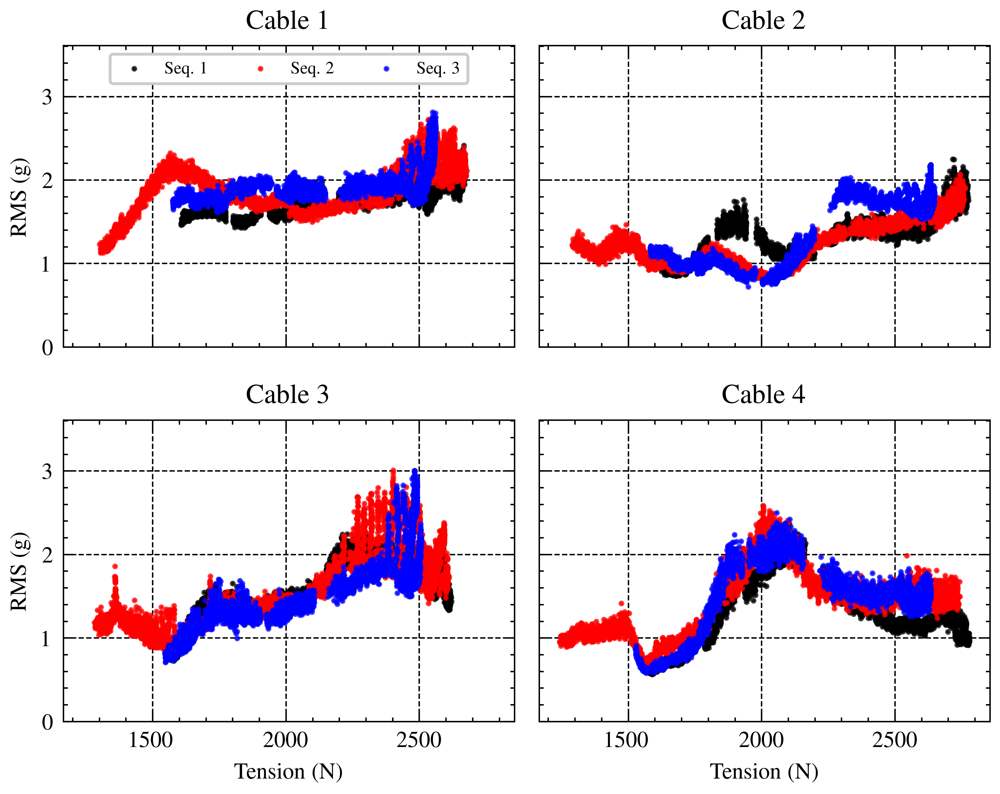

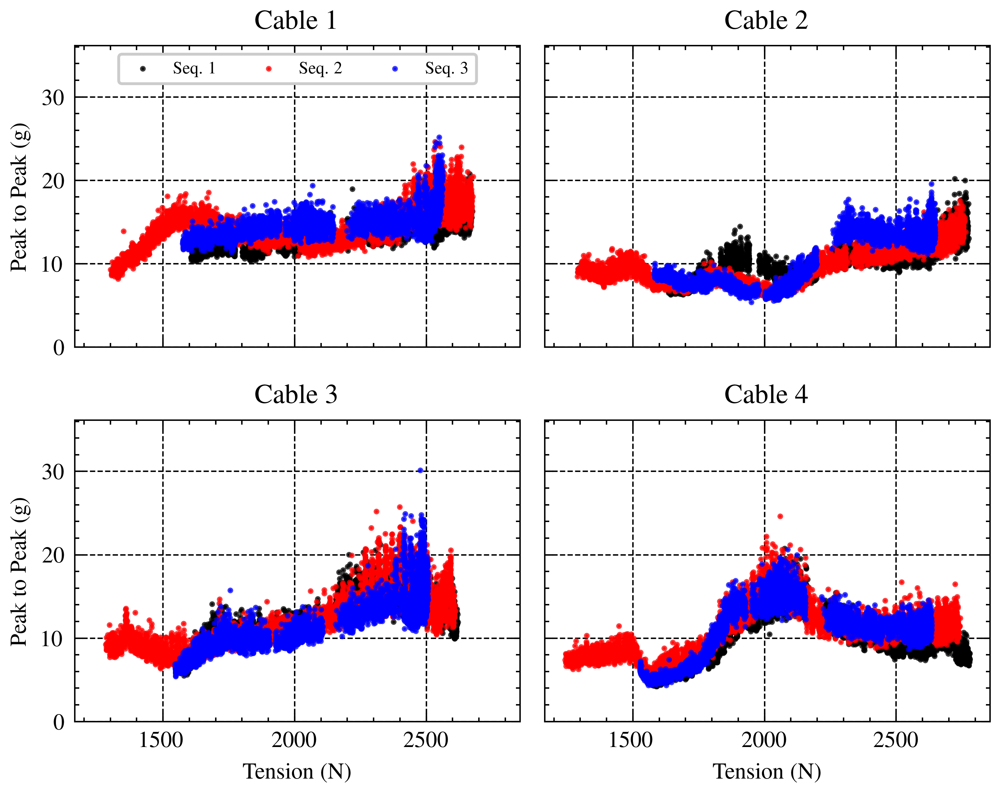

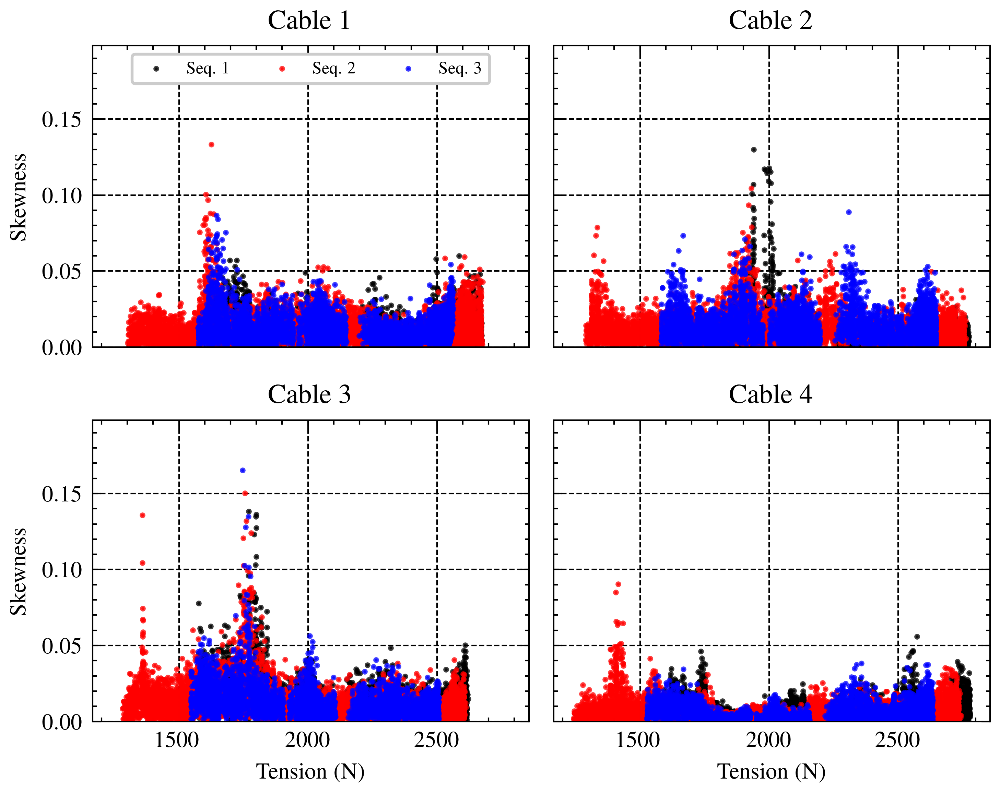

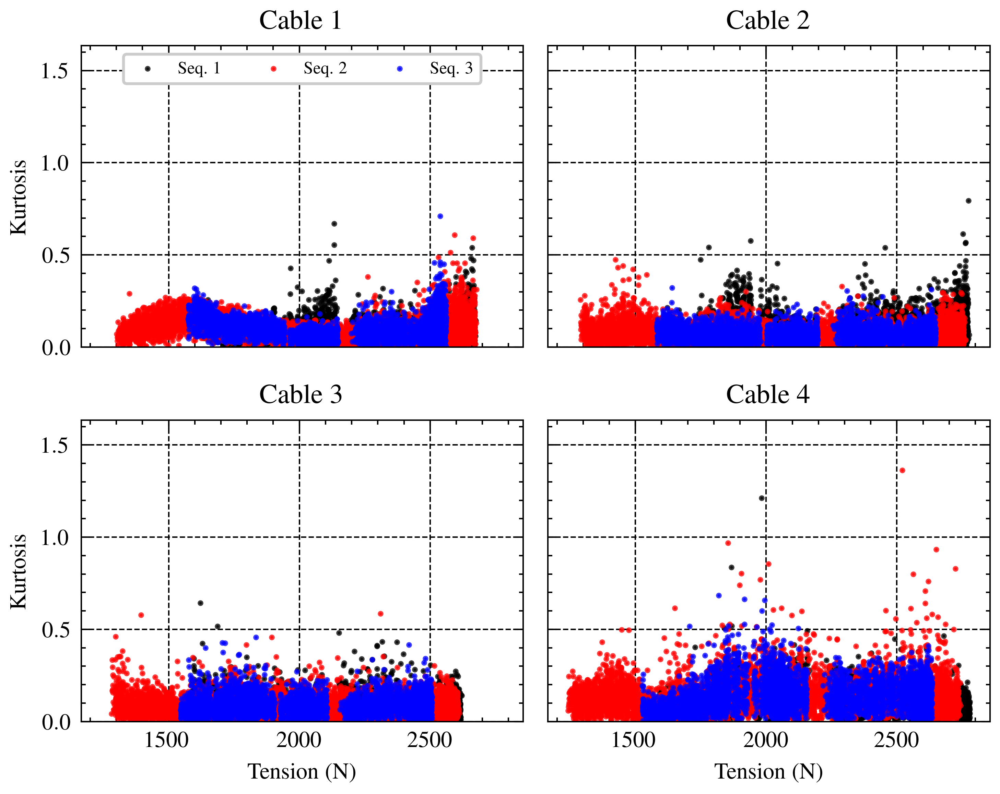

In [110]:
plot_comparison_over_tension(df_radials, variable_to_be_plotted="rms", title="radial")
plot_comparison_over_tension(df_radials, "peak_to_peak", "radial")
plot_comparison_over_tension(df_radials, "skewness", "radial")
plot_comparison_over_tension(df_radials, "kurtosis", "radial")

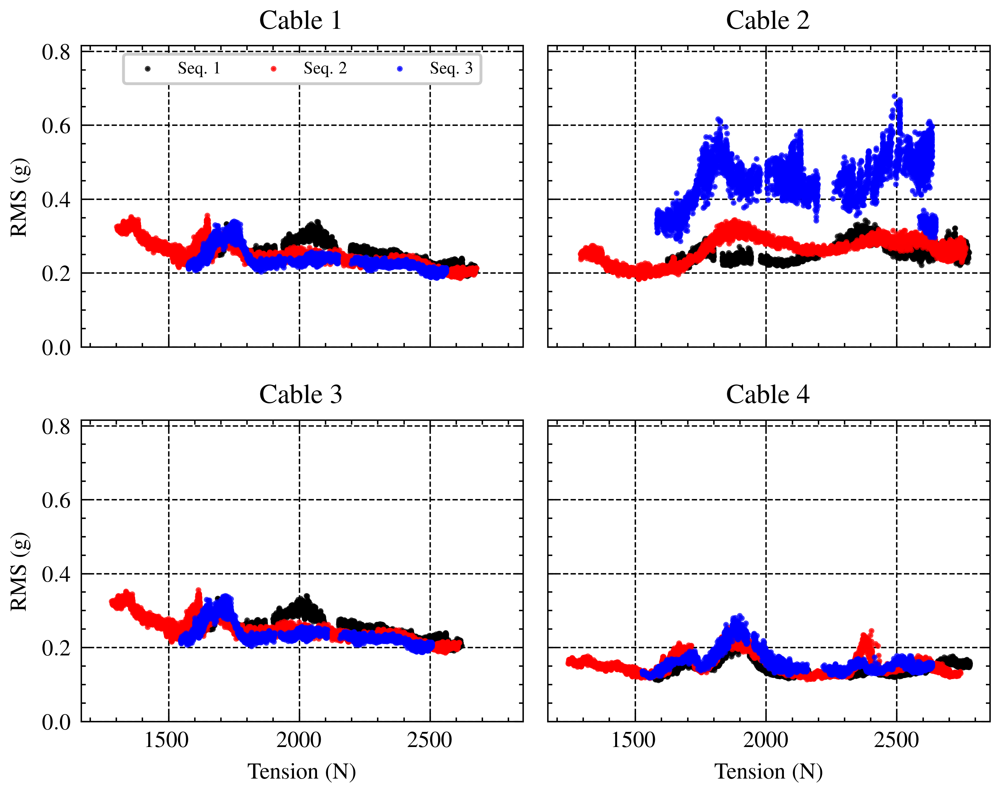

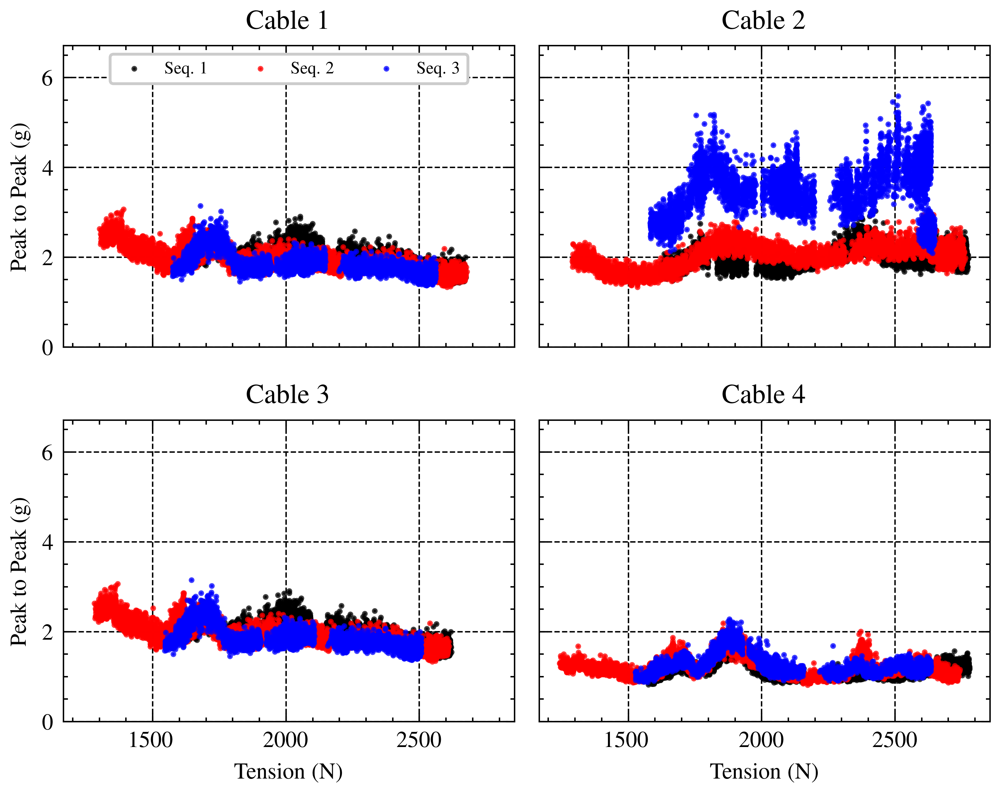

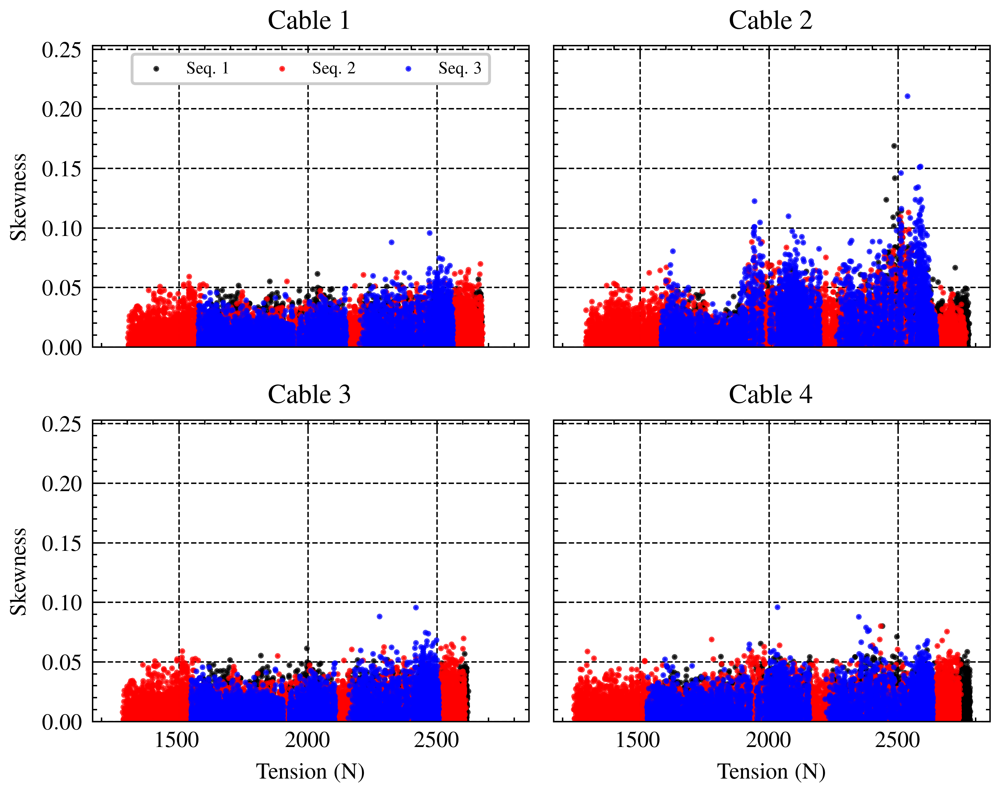

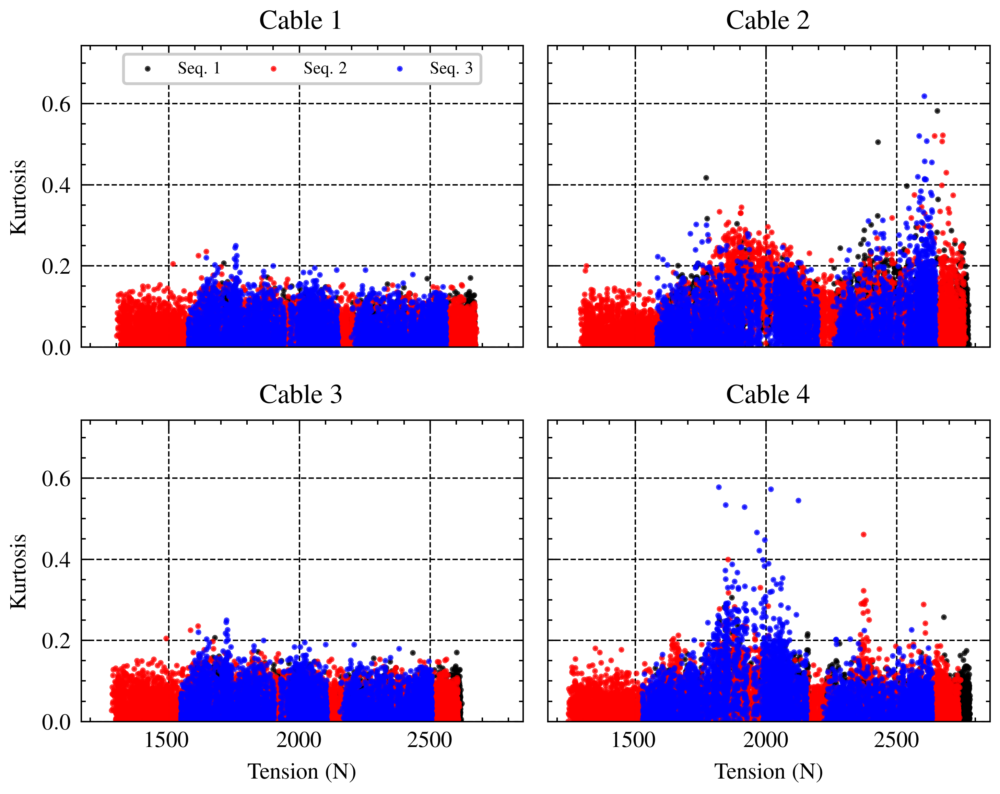

In [111]:
plot_comparison_over_tension(df_axial, variable_to_be_plotted="rms", title="axial")
plot_comparison_over_tension(df_axial, "peak_to_peak", "axial")
plot_comparison_over_tension(df_axial, "skewness", "axial")
plot_comparison_over_tension(df_axial, "kurtosis", "axial")